In [71]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression # 가장 많이 사용
from sklearn.neighbors import KNeighborsRegressor 
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동완성
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler# 정규화 클래스
from sklearn.preprocessing import OneHotEncoder # 원핫 인코딩
from sklearn.linear_model import Ridge # 릿지규제
from sklearn.linear_model import Lasso # 라쏘규제
from sklearn.model_selection import train_test_split
import numpy as np
from io import StringIO

In [90]:
# 데이터 가져오기
# manhattan.csv
# LinearRegression() 을 사용해서 랜탈비를 예측하시오
df = pd.read_csv('data/manhattan.csv',index_col='rental_id')
# 데이터 전처리
data = df.drop(columns=df.columns[[0,15,16]]).values 
data2 = df[['neighborhood','borough']].values
label = df['rent'].values
# len(df.columns)
df['neighborhood'].unique() # 32개
df['borough'].unique() # 1개

<StringArray>
['Manhattan']
Length: 1, dtype: str

In [91]:
neigbor = df['neighborhood'].to_numpy().reshape(-1,1)
encoder = OneHotEncoder(sparse_output=False,drop='first')
result = encoder.fit_transform(neigbor)
result

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(3539, 31))

In [92]:
total_data = np.concatenate((data,result),axis=1)
total_data

array([[0.00e+00, 1.00e+00, 4.80e+02, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       [2.00e+00, 2.00e+00, 2.00e+03, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       [1.00e+00, 1.00e+00, 9.16e+02, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       ...,
       [0.00e+00, 1.00e+00, 2.50e+02, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       [1.00e+00, 1.00e+00, 6.51e+02, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       [1.00e+00, 1.00e+00, 8.16e+02, ..., 0.00e+00, 0.00e+00, 0.00e+00]],
      shape=(3539, 45))

In [95]:
# 데이터 분리1
train_data,test_data,train_label,test_label = train_test_split(data,label)
train_data[0]

array([  0.,   1., 851.,   3.,  17.,  44.,   1.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.])

In [105]:
# 데이터 분리2
train_data,test_data,train_label,test_label = train_test_split(total_data,label)
train_data[0]

array([  1.,   1., 675.,   6.,   1.,  92.,   0.,   0.,   1.,   0.,   0.,
         1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,
         0.])

In [106]:
poly = PolynomialFeatures(degree=2,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)


In [107]:
# 데이터 학습 
lr = LinearRegression()
lr.fit(train_poly,train_label)

# 데이터 예측
predict = lr.predict(test_poly)

# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
score,score2

(0.863062606069441, 0.8505827725374725)

In [101]:
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)
train_scaled

array([[-1.40068483, -0.60119339, -0.17697653, ..., -0.24301905,
        -0.14681636, -0.46149744],
       [-0.36230004, -0.60119339, -0.12479299, ..., -0.24301905,
        -0.14681636,  2.16685924],
       [-0.36230004, -0.60119339, -0.07469679, ..., -0.24301905,
        -0.14681636, -0.46149744],
       ...,
       [ 1.71446953,  1.07306397,  1.5555171 , ..., -0.24301905,
        -0.14681636,  2.16685924],
       [-0.36230004, -0.60119339, -0.35648792, ..., -0.24301905,
        -0.14681636, -0.46149744],
       [ 0.67608475,  1.07306397,  0.11525131, ...,  4.1149037 ,
        -0.14681636, -0.46149744]], shape=(2654, 119))

In [102]:
alpha_list = [0.001,0.01,0.1,1,10,100]

s_list = []
s_list1 = []

for a in alpha_list:
    ridge = Ridge(alpha=a)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    s_list.append(score)
    s_list1.append(score2)
s_list,s_list1

([0.8191470005673231,
  0.819146997559037,
  0.8191467028283121,
  0.8191221965384876,
  0.818213346013675,
  0.8091263777437652],
 [0.7977390312919616,
  0.7977405298841898,
  0.7977546084718466,
  0.7978214715040965,
  0.796437531227419,
  0.7851719664233331])

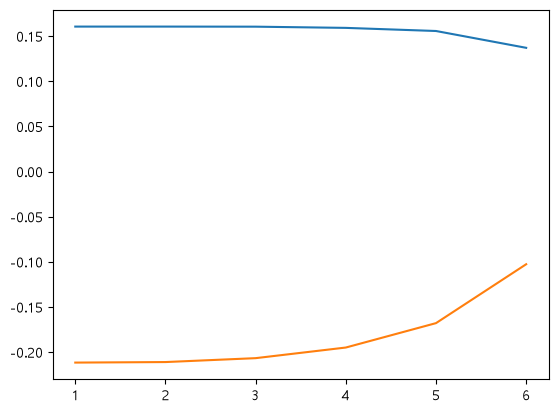

In [98]:
list = [1,2,3,4,5,6]
plt.plot(list,s_list)
plt.plot(list,s_list1)


In [104]:
# 데이터 학습
ridge = Ridge(alpha=100)
ridge.fit(train_scaled,train_label)

# 데이터 예측
predict = ridge.predict(test_scaled)

# 정확도
scor = ridge.score(train_scaled,train_label)
scor2 = ridge.score(test_scaled,test_label)
scor,scor2

(0.8091263777437652, 0.7851719664233331)